**Exploratory Data Analysis(EDA)**

In [104]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


In [105]:
df = pd.read_csv('/content/bytebrew-campus-cafe-orders.csv')

In [106]:
df.head()

,order_id,day_of_week,time_slot,student_year,faculty,drink,size,food_item,is_member,payment,raining,price,prep_minutes,calories,tip,rating,study_hours_today,prior_coffee_cups
0,B0301,Tue,late_night,2,Bio,tea,L,croissant,no,card,no,4.49,8,288,0.10,3.0,1.9,1
1,B0266,Tue,morning,2,Bio,cappuccino,L,sandwich,no,campus_card,no,8.16,6,558,0.67,4.0,1.3,3
2,B0064,Fri,late_night,1,Business,hot_chocolate,S,cookie,no,campus_card,yes,4.08,8,382,0.84,4.0,4.8,0
3,B0197,Thu,afternoon,4,Business,americano,S,cookie,yes,card,no,3.19,6,194,0.89,4.0,3.2,0
4,B0261,Fri,morning,2,Design,americano,M,none,yes,card,no,2.48,5,11,0.79,3.0,4.7,1


In [107]:
df.shape

(365, 18)

In [108]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   order_id           365 non-null    object 
 1   day_of_week        365 non-null    object 
 2   time_slot          365 non-null    object 
 3   student_year       365 non-null    int64  
 4   faculty            365 non-null    object 
 5   drink              365 non-null    object 
 6   size               365 non-null    object 
 7   food_item          365 non-null    object 
 8   is_member          365 non-null    object 
 9   payment            365 non-null    object 
 10  raining            365 non-null    object 
 11  price              365 non-null    float64
 12  prep_minutes       365 non-null    int64  
 13  calories           365 non-null    int64  
 14  tip                336 non-null    float64
 15  rating             356 non-null    float64
 16  study_hours_today  365 non

In [109]:
df.describe()

,student_year,price,prep_minutes,calories,tip,rating,study_hours_today,prior_coffee_cups
count,365.000000,365.000000,365.000000,365.000000,336.000000,356.000000,365.000000,365.000000
mean,2.224658,4.903836,5.980822,294.487671,0.570208,3.904494,3.705479,1.320548
std,1.086351,1.986780,2.434226,193.690356,0.339604,0.751998,1.451135,1.108776
min,1.000000,1.610000,1.000000,0.000000,0.000000,2.000000,0.300000,0.000000
25%,1.000000,3.220000,4.000000,141.000000,0.310000,3.000000,2.700000,0.000000
50%,2.000000,4.480000,6.000000,288.000000,0.580000,4.000000,3.600000,1.000000
75%,3.000000,6.570000,8.000000,436.000000,0.802500,4.000000,4.600000,2.000000
max,4.000000,9.340000,12.000000,747.000000,1.560000,5.000000,8.000000,4.000000


In [110]:
df.columns.tolist()

['order_id',
 'day_of_week',
 'time_slot',
 'student_year',
 'faculty',
 'drink',
 'size',
 'food_item',
 'is_member',
 'payment',
 'raining',
 'price',
 'prep_minutes',
 'calories',
 'tip',
 'rating',
 'study_hours_today',
 'prior_coffee_cups']

In [111]:
df['day_of_week'].value_counts()

,count
day_of_week,
Fri,72
Tue,60
Thu,56
Wed,54
Mon,43
Sat,42
Sun,38


In [112]:
df['drink'].value_counts()

,count
drink,
cappuccino,60
cold_brew,57
latte,53
smoothie,53
tea,50
americano,47
hot_chocolate,45


In [113]:
df['food_item'].unique()

array(['croissant', 'sandwich', 'cookie', 'none', 'soup', 'salad'],
      dtype=object)

In [114]:
df['food_item'].value_counts()

,count
food_item,
none,145
sandwich,73
croissant,54
salad,39
cookie,38
soup,16


In [115]:
df['time_slot'].value_counts()

,count
time_slot,
evening,99
afternoon,95
morning,93
late_night,78


**Легкая очистка**

In [116]:
print(df.isna().sum())

order_id              0
day_of_week           0
time_slot             0
student_year          0
faculty               0
drink                 0
size                  0
food_item             0
is_member             0
payment               0
raining               0
price                 0
prep_minutes          0
calories              0
tip                  29
rating                9
study_hours_today     0
prior_coffee_cups     0
dtype: int64


In [117]:
print(df.duplicated().sum())

5


**Очистка**

In [118]:
df_clean = df.drop_duplicates().copy()
print("Shape after drop", df_clean.shape)

Shape after drop (360, 18)


In [119]:
tip_median = df_clean['tip'].median()
print('tip med', tip_median)

df_clean['tip'] = df_clean['tip'].fillna(tip_median)


tip med 0.58


In [120]:
rating_median = df_clean['rating'].median()
print('rate med', rating_median)

df_clean['rating'] = df_clean['rating'].fillna(rating_median)

rate med 4.0


In [121]:
print(df_clean.isna().sum())

order_id             0
day_of_week          0
time_slot            0
student_year         0
faculty              0
drink                0
size                 0
food_item            0
is_member            0
payment              0
raining              0
price                0
prep_minutes         0
calories             0
tip                  0
rating               0
study_hours_today    0
prior_coffee_cups    0
dtype: int64


5. Анализы: фильтры и groupby
Несколько коротких вопросов к данным — по одной идее на ячейку.

5.1. Средний чек у членов программы лояльности и остальных

In [122]:
list_is_memb = df_clean[df_clean['is_member'] == 'yes']
list_isnt_memb = df_clean[df_clean['is_member'] == 'no']

mean_isnt_memb = list_isnt_memb['price'].mean()
mean_is_memb = list_is_memb['price'].mean()

print("Средний чек членов программы",mean_is_memb)
print("Средний чек остальных",mean_isnt_memb)

Средний чек членов программы 4.477950819672131
Средний чек остальных 5.11063025210084


5.2. Какие напитки берут вечером и ночью?

In [123]:
evening_drinks_night = df_clean[(df_clean['time_slot'] == 'evening') | (df_clean['time_slot'] == 'night')]
print(evening_drinks_night['drink'].unique())


['cappuccino' 'americano' 'hot_chocolate' 'latte' 'tea' 'cold_brew'
 'smoothie']



5.3. Среднее время приготовления по типу еды

In [124]:
for typ_food, row in df_clean.groupby('food_item'):
  print(typ_food, round(row['prep_minutes'].mean(),2))

cookie 6.95
croissant 7.57
none 4.1
salad 7.51
sandwich 6.9
soup 7.33


5.4. Дождь и горячий шоколад — совпадение?

In [125]:
print(df_clean[(df_clean['raining'] == 'yes') & (df_clean['drink'] == 'hot chocolate')].shape)




(0, 18)


5.5. Курс студента и средний рейтинг / чаевые

In [126]:
for rait, row in df_clean.groupby('student_year'):
  print(rait,"rait", row['rating'].mean(), "tip", row['tip'].mean())

1 rait 3.877049180327869 tip 0.5331147540983606
2 rait 3.903225806451613 tip 0.6116129032258064
3 rait 3.9886363636363638 tip 0.6047727272727272
4 rait 3.8596491228070176 tip 0.5245614035087719


5.6. Факультет и калории (кто «слаще» заказывает?)

In [127]:
print(max(df_clean.groupby('faculty')['calories'].mean()))


315.12068965517244


6. Графики
Подписываем оси и заголовки. Без лишнего декора. Каждую диаграмму следет построить через plt и seaborn

6.1. Гистограмма цены

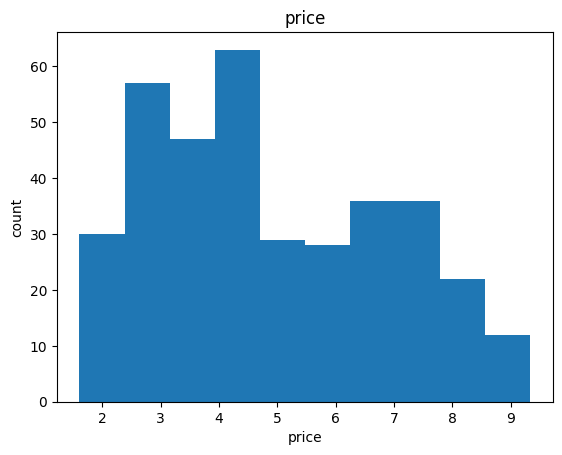

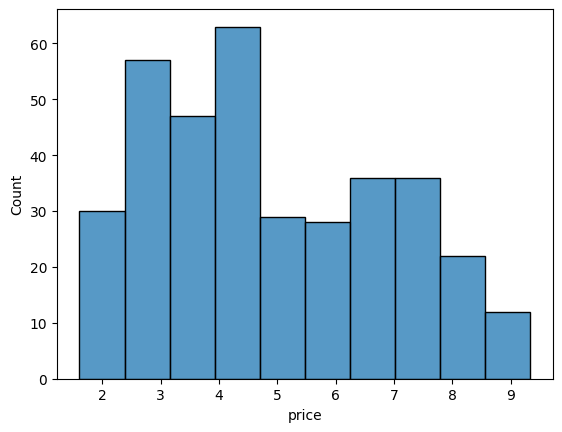

In [128]:
plt.hist(df_clean['price'])
plt.title("price")
plt.xlabel("price")
plt.ylabel("count")
plt.show()

sns.histplot(df_clean['price'])
plt.show()

6.2. Столбчатая диаграмма: заказы по дням недели

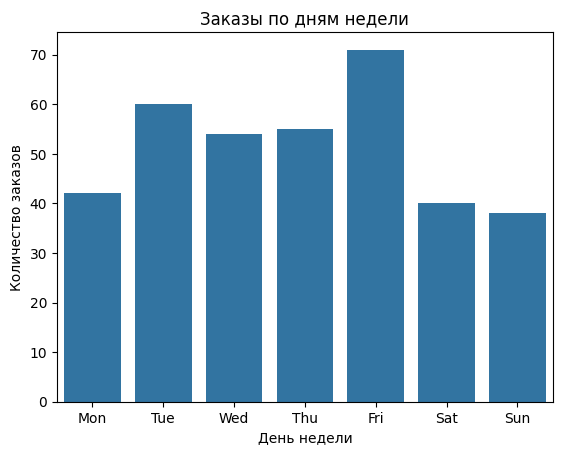

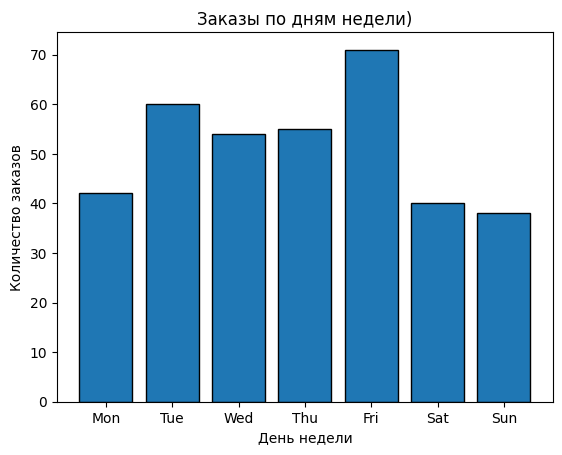

In [129]:
order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

sns.countplot(data=df_clean, x='day_of_week', order=order)
plt.title('Заказы по дням недели')
plt.xlabel('День недели')
plt.ylabel('Количество заказов')
plt.show()

counts = df_clean['day_of_week'].value_counts().reindex(order)

plt.bar(counts.index, counts.values, edgecolor='black')
plt.title('Заказы по дням недели)')
plt.xlabel('День недели')
plt.ylabel('Количество заказов')
plt.show()

6.3. Средняя цена по напитку (barh удобнее читать)

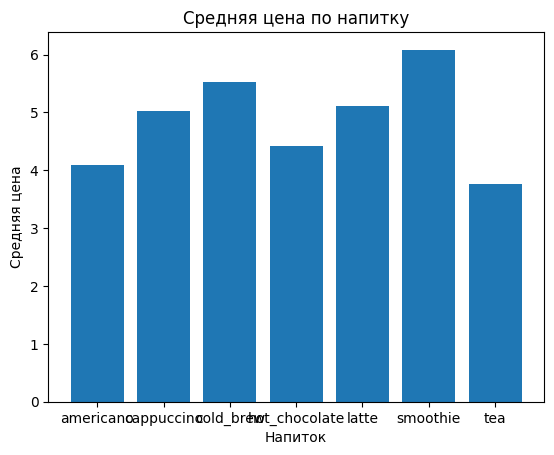

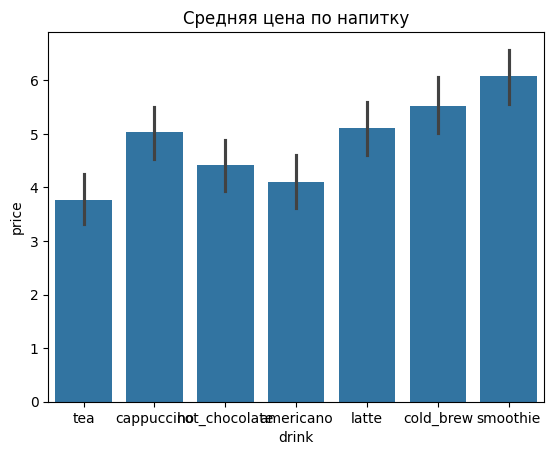

In [130]:
mean_price = df_clean.groupby('drink')['price'].mean()

plt.bar(mean_price.index, mean_price.values)
plt.title('Средняя цена по напитку')
plt.xlabel('Напиток')
plt.ylabel('Средняя цена')
plt.show()

sns.barplot(data = df_clean, x='drink', y='price')
plt.title('Средняя цена по напитку')
plt.show()


6.4. Scatter: время приготовления vs рейтинг

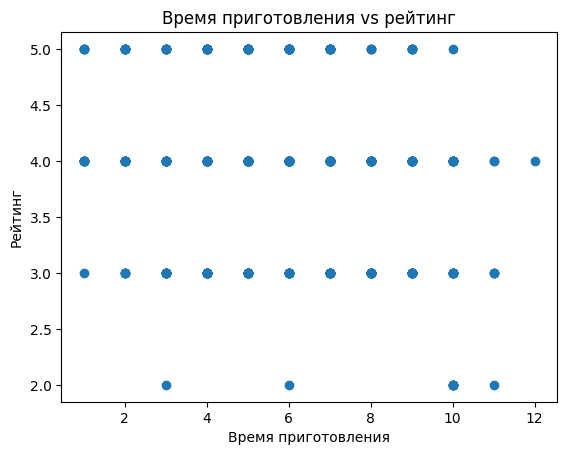

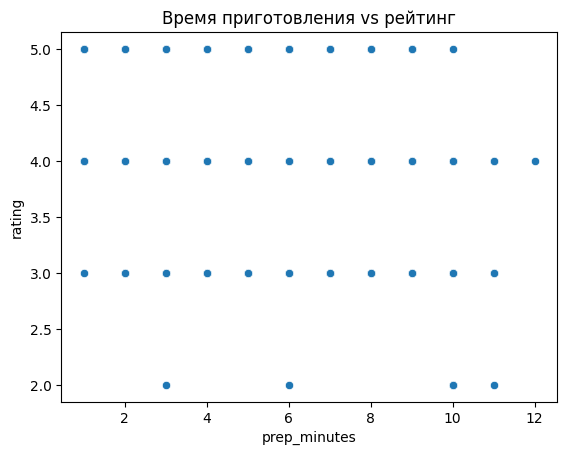

In [131]:
plt.scatter(df_clean['prep_minutes'], df_clean['rating'])
plt.title('Время приготовления vs рейтинг')
plt.xlabel('Время приготовления')
plt.ylabel('Рейтинг')
plt.show()

sns.scatterplot(data=df_clean, x='prep_minutes', y='rating')
plt.title('Время приготовления vs рейтинг')
plt.show()

6.5. Boxplot калорий по размеру стакана

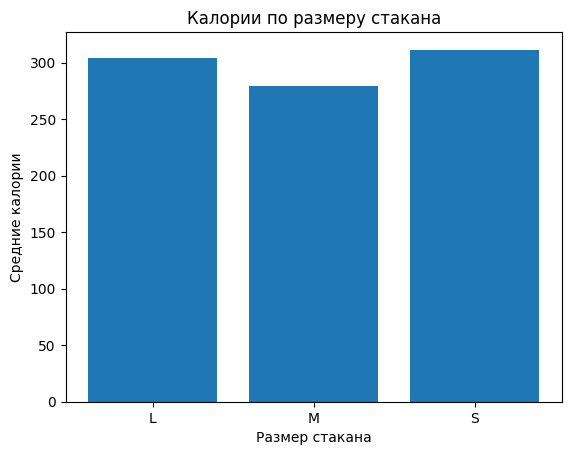

In [132]:
mean_cal = df_clean.groupby('size')['calories'].mean()

plt.bar(mean_cal.index, mean_cal.values)
plt.title('Калории по размеру стакана')
plt.xlabel('Размер стакана')
plt.ylabel('Средние калории')
plt.show()

6.6. Связь учёбы и кофе: study hours vs prior cups (scatter + лёгкий цвет по member)

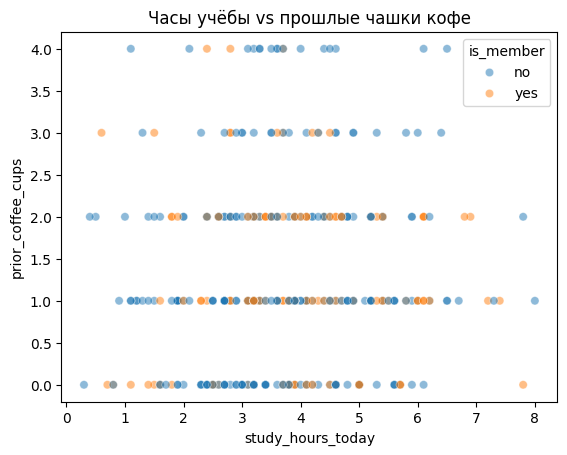

In [134]:
sns.scatterplot(data=df_clean, x='study_hours_today', y='prior_coffee_cups', hue='is_member', alpha=0.5)
plt.title('Часы учёбы vs прошлые чашки кофе')
plt.show()

Задание A
Посчитайте средний tip для каждого способа оплаты (payment).
Отсортируйте по убыванию среднего чаевого. Постройте bar chart.

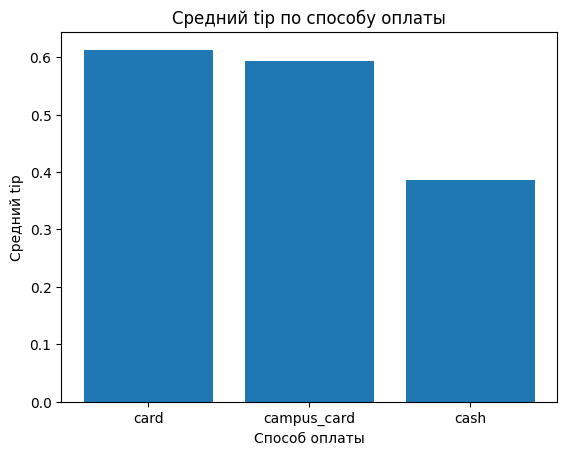

In [135]:
mean_tip = df_clean.groupby('payment')['tip'].mean().sort_values(ascending=False)

plt.bar(mean_tip.index, mean_tip.values)
plt.title('Средний tip по способу оплаты')
plt.xlabel('Способ оплаты')
plt.ylabel('Средний tip')
plt.show()

Задание B
Сделайте фильтр: только заказы с едой (food_item != "none") и time_slot == "morning".
Сколько таких строк? Какой самый частый drink в этом срезе?

In [138]:
noneFoodandMorn = df_clean[(df_clean['food_item'] != 'none') & (df_clean['time_slot'] == 'morning')]

print(noneFoodandMorn['drink'].value_counts())

drink
cappuccino       13
latte            11
tea               9
smoothie          7
hot_chocolate     7
americano         6
cold_brew         5
Name: count, dtype: int64


### Что означают столбцы?

| Столбец | Смысл |
|---------|--------|
| `order_id` | идентификатор заказа |
| `day_of_week` | день недели |
| `time_slot` | время суток: morning / afternoon / evening / late_night |
| `student_year` | курс обучения (1–4) |
| `faculty` | факультет |
| `drink` | напиток |
| `size` | размер S / M / L |
| `food_item` | еда (`none`, если только напиток) |
| `is_member` | есть ли карта лояльности |
| `payment` | способ оплаты |
| `raining` | шёл ли дождь в тот день |
| `price` | цена заказа |
| `prep_minutes` | время приготовления (мин) |
| `calories` | оценка калорий |
| `tip` | чаевые |
| `rating` | оценка сервиса 1–5 |
| `study_hours_today` | сколько часов студент уже учился сегодня |
| `prior_coffee_cups` | сколько кофе уже было до этого заказа